# Heparin: cross-fitted CATE vs placebo

Same analysis as notebook 06, with heparin as the treatment under study: any dose (low or medium) against none. Aspirin, randomised independently, is among the features.

Two things differ from notebook 06.

- The average effect of heparin on death or dependency at 6 months is zero in the trial, so the only question is whether some patients benefit while others are harmed.
- Deciles are formed within each cross-fitting fold (`fold_ids`), not across all folds together. Each fold's model mostly predicts the average effect of its own training data, and the held-out fold's average effect is mechanically anti-correlated with it, because their weighted sum is the overall ATE. Ranking all folds together lets this between-fold shift into the ordering and produces a spurious reversed trend for learners with a narrow CATE distribution (S-learner, causal forest). Ranking within fold removes it.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier

from ml_med.modeling import (
    bootstrap_uplift,
    cross_fit_cate,
    fold_ids,
    prepare_data,
    split_train_test,
    uplift_by_decile,
)

FEATURES_PATH = Path("../data/processed/ist_features.parquet")

In [2]:
df = pd.read_parquet(FEATURES_PATH)
X, y, t = prepare_data(df, "RXHEP")
X_train, X_test, y_train, y_test, t_train, t_test = split_train_test(X, y, t)

In [3]:
candidates = {
    "logistic": None,
    "random_forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=20, random_state=0, n_jobs=-1
    ),
    "gradient_boosting": HistGradientBoostingClassifier(random_state=0),
}

In [4]:
cates = {}

t_placebo = t_train.sample(frac=1, random_state=0).set_axis(t_train.index)
cates["placebo"] = cross_fit_cate(X_train, y_train, t_placebo, "RXHEP")

for learner in ("t", "s"):
    for name, clf in candidates.items():
        cates[f"{learner}_{name}"] = cross_fit_cate(
            X_train, y_train, t_train, "RXHEP", clf=clf, learner=learner
        )

cates["causal_forest"] = cross_fit_cate(
    X_train, y_train, t_train, "RXHEP", learner="cf"
)

fold = fold_ids(X_train)
pd.DataFrame({name: c.describe() for name, c in cates.items()}).round(3)

,placebo,t_logistic,t_random_forest,t_gradient_boosting,s_logistic,s_random_forest,s_gradient_boosting,causal_forest
count,15428.000,15428.000,15428.000,15428.000,15428.000,15428.000,15428.000,15428.000
mean,-0.000,0.002,0.003,0.004,0.002,0.001,0.002,0.002
std,0.050,0.046,0.046,0.131,0.006,0.015,0.015,0.013
min,-0.349,-0.307,-0.188,-0.665,-0.009,-0.077,-0.149,-0.045
25%,-0.026,-0.017,-0.025,-0.066,-0.003,-0.006,0.000,-0.007
50%,0.001,0.007,0.004,0.002,0.003,0.002,0.000,0.003
75%,0.026,0.027,0.033,0.070,0.007,0.010,0.000,0.011
max,0.290,0.371,0.174,0.697,0.011,0.076,0.162,0.042


In [5]:
uplifts = {}
uplifts["placebo"] = uplift_by_decile(cates["placebo"], y_train, t_placebo, fold=fold)

for name, cate in cates.items():
    t = t_placebo if name == "placebo" else t_train
    uplifts[name] = uplift_by_decile(cate, y_train, t, fold=fold)

pd.DataFrame({name: u["uplift"] for name, u in uplifts.items()}).round(3)

,placebo,t_logistic,t_random_forest,t_gradient_boosting,s_logistic,s_random_forest,s_gradient_boosting,causal_forest
decile,,,,,,,,
1,-0.030,-0.035,0.007,0.021,-0.004,-0.015,-0.021,0.023
2,-0.041,-0.011,0.024,-0.007,0.022,0.010,0.001,0.023
3,0.030,0.024,0.002,-0.013,-0.048,0.045,-0.034,0.011
4,-0.036,-0.004,-0.016,0.009,0.046,-0.025,0.008,-0.002
5,0.045,0.012,-0.047,-0.053,-0.011,0.014,-0.024,-0.014
6,0.015,0.036,0.035,0.004,-0.005,-0.001,-0.010,0.011
7,0.013,-0.030,0.014,0.028,-0.001,0.010,0.051,0.011
8,-0.025,0.024,-0.013,-0.002,-0.029,-0.020,0.001,0.004
9,0.008,-0.012,-0.001,-0.013,0.017,-0.027,0.020,-0.062


In [6]:
uplifts["causal_forest"].round(3)

,n,cate_mean,rate_control,rate_treated,uplift
decile,,,,,
1,1543,-0.017,0.494,0.516,0.023
2,1543,-0.010,0.571,0.593,0.023
3,1543,-0.006,0.598,0.610,0.011
4,1542,-0.003,0.632,0.630,-0.002
5,1543,0.000,0.659,0.645,-0.014
6,1543,0.003,0.662,0.672,0.011
7,1542,0.006,0.639,0.649,0.011
8,1543,0.010,0.673,0.677,0.004
9,1543,0.014,0.691,0.629,-0.062


In [7]:
boot = bootstrap_uplift(cates["causal_forest"], y_train, t_train, fold=fold)
print(boot.shape)
boot.std().round(3)

(1000, 10)


decile
1     0.026
2     0.026
3     0.026
4     0.025
5     0.025
6     0.025
7     0.027
8     0.025
9     0.025
10    0.024
dtype: float64

In [8]:
diff = boot[[1, 2, 3, 4, 5]].mean(axis=1) - boot[[6, 7, 8, 9, 10]].mean(axis=1)

print("mean difference:", round(diff.mean(), 3))
print("95% interval:", diff.quantile([0.025, 0.975]).round(3).tolist())
print("share of resamples with the opposite sign:", (diff >= 0).mean())

mean difference: 0.019
95% interval: [-0.012, 0.048]
share of resamples with the opposite sign: 0.892


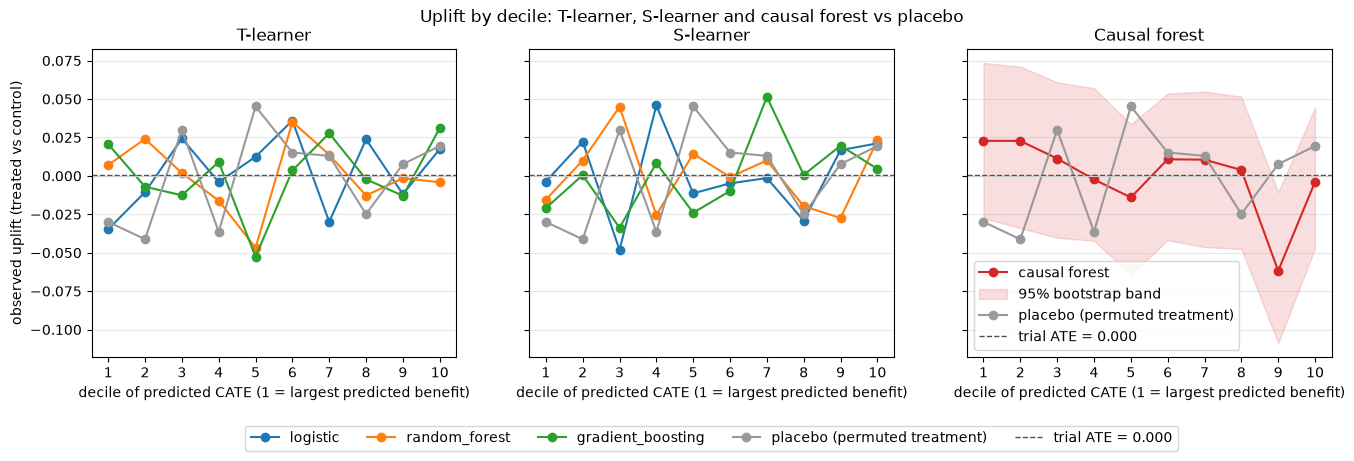

In [9]:
ate = y_train[t_train == 1].mean() - y_train[t_train == 0].mean()
colors = {
    "logistic": "tab:blue",
    "random_forest": "tab:orange",
    "gradient_boosting": "tab:green",
}
titles = {"t": "T-learner", "s": "S-learner", "cf": "Causal forest"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, learner in zip(axes, ("t", "s", "cf")):
    if learner == "cf":
        u = uplifts["causal_forest"]
        ax.plot(
            u.index, u["uplift"], marker="o", color="tab:red", label="causal forest"
        )
        band = boot.quantile([0.025, 0.975])
        ax.fill_between(
            u.index,
            band.loc[0.025],
            band.loc[0.975],
            color="tab:red",
            alpha=0.15,
            label="95% bootstrap band",
        )
    else:
        for clf_name, color in colors.items():
            u = uplifts[f"{learner}_{clf_name}"]
            ax.plot(u.index, u["uplift"], marker="o", color=color, label=clf_name)
    u = uplifts["placebo"]
    ax.plot(
        u.index,
        u["uplift"],
        marker="o",
        color="0.6",
        label="placebo (permuted treatment)",
    )
    ax.axhline(
        ate, linestyle="--", color="0.3", linewidth=1, label=f"trial ATE = {ate:.3f}"
    )
    ax.axhline(0, color="0.8", linewidth=0.8)
    ax.set_xticks(u.index)
    ax.set_xlabel("decile of predicted CATE (1 = largest predicted benefit)")
    ax.set_title(titles[learner])
    ax.grid(axis="y", alpha=0.3)

axes[0].set_ylabel("observed uplift (treated vs control)")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=5)
axes[2].legend(loc="best")
fig.suptitle("Uplift by decile: T-learner, S-learner and causal forest vs placebo")
plt.show()

## Conclusion

1. Every learner recovers the null average effect. The mean cross-fitted CATE is about 0.002 for all seven learners, and the trial ATE is 0.000.

2. No learner orders patients better than chance. For the causal forest the predicted CATE spans −0.017 to +0.021, but the observed uplift does not follow it: decile 1, the largest predicted benefit, shows +0.023. The one large value, −0.062 in decile 9, sits where the forest predicted harm.

3. Bootstrap. Deciles 1–5 minus deciles 6–10 is +0.016 (bootstrap mean +0.019, 95% interval −0.012 to +0.048): compatible with zero and, if anything, opposite to the forest's ordering.

4. Verdict. On the primary outcome heparin has no average effect, and none of the seven learners identifies patients who benefit. Heterogeneity may still exist in the components that the primary outcome nets out (fewer recurrent strokes, more bleeding); they are not explored here.